In [1]:
import pandas as pd

population_df = pd.read_csv(
    "CommunityDistrictAgePopulation2023.csv"
)

mortality_df = pd.read_csv(
    "CommunityDistrictSingleYearCounts2023.csv"
)

In [2]:
print(mortality_df.columns.tolist())

['commntydst', 'Male', 'Female', 'Age<=28days', 'Age 1-12months', 'Age 1-4', 'Age 5-9', 'Age 10-14', 'Age 15-19', 'Age 20-24', 'Age 25-29', 'Age 30-34', 'Age 35-39', 'Age 40-44', 'Age 45-49', 'Age 50-54', 'Age 55-59', 'Age 60-64', 'Age 65-69', 'Age 70-74', 'Age 75-79', 'Age 80-84', 'Age 85+', 'Age Unkown', 'Male_Age<=28days', 'Male_Age 1-12months', 'Male_Age 1-4', 'Male_Age 5-9', 'Male_Age 10-14', 'Male_Age 15-19', 'Male_Age 20-24', 'Male_Age 25-29', 'Male_Age 30-34', 'Male_Age 35-39', 'Male_Age 40-44', 'Male_Age 45-49', 'Male_Age 50-54', 'Male_Age 55-59', 'Male_Age 60-64', 'Male_Age 65-69', 'Male_Age 70-74', 'Male_Age 75-79', 'Male_Age 80-84', 'Male_Age 85+', 'Male_Age Unkown', 'Female_Age<=28days', 'Female_Age 1-12months', 'Female_Age 1-4', 'Female_Age 5-9', 'Female_Age 10-14', 'Female_Age 15-19', 'Female_Age 20-24', 'Female_Age 25-29', 'Female_Age 30-34', 'Female_Age 35-39', 'Female_Age 40-44', 'Female_Age 45-49', 'Female_Age 50-54', 'Female_Age 55-59', 'Female_Age 60-64', 'Female_A

In [3]:
mortality_df.head(10)

,commntydst,Male,Female,Age<=28days,Age 1-12months,Age 1-4,Age 5-9,Age 10-14,Age 15-19,Age 20-24,...,Deaths due to assault(homicide)_Hispanic,Deaths due to assault(homicide)_Asian Non-Hispanic,Deaths due to assault(homicide)_White Non-Hispanic,Deaths due to assault(homicide)_Black Non-Hispanic,Deaths due to assault(homicide)_Other race/ethnicity or not known,Other causes_Hispanic,Other causes_Asian Non-Hispanic,Other causes_White Non-Hispanic,Other causes_Black Non-Hispanic,Other causes_Other race/ethnicity or not known
0,101,85,85,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,12.0,28.0,NaN,NaN
1,102,204,183,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,8.0,12.0,76.0,NaN,5.0
2,103,599,581,NaN,NaN,NaN,NaN,NaN,NaN,7.0,...,NaN,NaN,NaN,NaN,NaN,77.0,101.0,71.0,22.0,8.0
3,104,323,255,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,30.0,13.0,80.0,24.0,6.0
4,105,129,93,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,33.0,10.0,NaN
5,106,340,373,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,11.0,17.0,159.0,7.0,7.0
6,107,687,712,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,58.0,16.0,242.0,48.0,20.0
7,108,645,683,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,21.0,19.0,284.0,19.0,11.0
8,109,298,280,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,64.0,6.0,21.0,62.0,6.0
9,110,434,425,NaN,NaN,NaN,NaN,NaN,5.0,5.0,...,NaN,NaN,NaN,15.0,NaN,26.0,NaN,9.0,154.0,8.0


In [6]:
import pandas as pd

population_df = pd.read_csv(
    "CommunityDistrictAgePopulation2023.csv"
)

mortality_df = pd.read_csv(
    "CommunityDistrictSingleYearCounts2023.csv"
)

mortality_df = mortality_df.rename(
    columns={"commntydst": "Community_District"}
)

population_df["Community_District"] = pd.to_numeric(
    population_df["Community_District"]
)

mortality_df["Community_District"] = pd.to_numeric(
    mortality_df["Community_District"], errors="coerce"
)

In [7]:
population_age_groups = {
    "Under_5": ["Under_5"],
    "5_14": ["5_9", "10_14"],
    "15_24": ["15_17", "18_19", "20", "21", "22_24"],
    "25_34": ["25_29", "30_34"],
    "35_44": ["35_39", "40_44"],
    "45_54": ["45_49", "50_54"],
    "55_64": ["55_59", "60_61", "62_64"],
    "65_74": ["65_66", "67_69", "70_74"],
    "75_84": ["75_79", "80_84"],
    "85_Plus": ["85_and_Over"]
}

population_standardized = population_df[
    ["Community_District", "Total_population"]
].copy()

for age_group, columns in population_age_groups.items():

    population_standardized[age_group] = (
        population_df[columns]
        .sum(axis=1, min_count=len(columns))
    )

population_standardized.head()

,Community_District,Total_population,Under_5,5_14,15_24,25_34,35_44,45_54,55_64,65_74,75_84,85_Plus
0,101,71865,3466,5743,9048,17616,13653,9566,5925,3622,2178,1048
1,102,86202,2375,4225,10977,21172,12446,11382,8667,8832,4784,1342
2,103,153288,4316,10072,20789,33570,18932,15777,19461,17241,8449,4681
3,104,117099,3151,5086,9316,32914,17707,14247,15447,12002,5533,1696
4,105,51619,1273,2201,5572,13575,8741,6321,5491,5141,2227,1077


In [8]:
mortality_age_groups = {
    "Under_5": ["Age<=28days", "Age 1-12months", "Age 1-4"],
    "5_14": ["Age 5-9", "Age 10-14"],
    "15_24": ["Age 15-19", "Age 20-24"],
    "25_34": ["Age 25-29", "Age 30-34"],
    "35_44": ["Age 35-39", "Age 40-44"],
    "45_54": ["Age 45-49", "Age 50-54"],
    "55_64": ["Age 55-59", "Age 60-64"],
    "65_74": ["Age 65-69", "Age 70-74"],
    "75_84": ["Age 75-79", "Age 80-84"],
    "85_Plus": ["Age 85+"]
}

# Keep only the 59 community districts
mortality_df = mortality_df[
    mortality_df["Community_District"].isin(
        population_df["Community_District"]
    )
].copy()

mortality_standardized = mortality_df[
    ["Community_District"]
].copy()

for age_group, columns in mortality_age_groups.items():

    mortality_standardized[age_group] = (
        mortality_df[columns]
        .apply(pd.to_numeric, errors="coerce")
        .sum(axis=1, min_count=len(columns))
    )

mortality_standardized["Total_Deaths"] = (
    pd.to_numeric(mortality_df["Male"], errors="coerce")
    + pd.to_numeric(mortality_df["Female"], errors="coerce")
)

mortality_standardized["Unknown_Age_Deaths"] = (
    pd.to_numeric(mortality_df["Age Unkown"], errors="coerce")
)

mortality_standardized.head()

,Community_District,Under_5,5_14,15_24,25_34,35_44,45_54,55_64,65_74,75_84,85_Plus,Total_Deaths,Unknown_Age_Deaths
0,101,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23,47,72,170,NaN
1,102,NaN,NaN,NaN,NaN,NaN,13.0,27.0,50,116,165,387,NaN
2,103,NaN,NaN,NaN,18.0,30.0,41.0,131.0,201,283,463,1180,NaN
3,104,NaN,NaN,NaN,11.0,23.0,40.0,67.0,120,141,172,578,NaN
4,105,NaN,NaN,NaN,NaN,NaN,NaN,28.0,43,60,72,222,NaN


In [9]:
standard_age_groups = list(population_age_groups.keys())

population_difference = (
    population_standardized["Total_population"]
    - population_standardized[standard_age_groups].sum(
        axis=1, min_count=10
    )
)

mortality_difference = (
    mortality_standardized["Total_Deaths"]
    - mortality_standardized[standard_age_groups].sum(
        axis=1, min_count=10
    )
    - mortality_standardized["Unknown_Age_Deaths"]
)

print("Population differences:")
print(population_difference.value_counts(dropna=False))

print("\nMortality differences:")
print(mortality_difference.value_counts(dropna=False))

print("\nDeaths with unknown age:")
print(mortality_standardized["Unknown_Age_Deaths"].sum())

print("\nMissing mortality values:")
print(mortality_standardized.isna().sum())

Population differences:
0    59
Name: count, dtype: int64

Mortality differences:
NaN    59
Name: count, dtype: int64

Deaths with unknown age:
0.0

Missing mortality values:
Community_District     0
Under_5               59
5_14                  59
15_24                 56
25_34                 16
35_44                  4
45_54                  2
55_64                  1
65_74                  0
75_84                  0
85_Plus                0
Total_Deaths           0
Unknown_Age_Deaths    59
dtype: int64


In [10]:
standard_weights = {
    "Under_5": 0.069181,
    "5_14": 0.145657,
    "15_24": 0.138646,
    "25_34": 0.135573,
    "35_44": 0.162613,
    "45_54": 0.134834,
    "55_64": 0.087247,
    "65_74": 0.066037,
    "75_84": 0.044842,
    "85_Plus": 0.015508
}

print("Sum of weights:", sum(standard_weights.values()))

Sum of weights: 1.000138


In [11]:
age_adjusted_df = population_standardized.merge(
    mortality_standardized,
    on="Community_District",
    how="left",
    suffixes=("_Population", "_Deaths"),
    validate="one_to_one",
    indicator=True
)

print(age_adjusted_df["_merge"].value_counts())

age_adjusted_df.head()

_merge
both          59
left_only      0
right_only     0
Name: count, dtype: int64


,Community_District,Total_population,Under_5_Population,5_14_Population,15_24_Population,25_34_Population,35_44_Population,45_54_Population,55_64_Population,65_74_Population,...,25_34_Deaths,35_44_Deaths,45_54_Deaths,55_64_Deaths,65_74_Deaths,75_84_Deaths,85_Plus_Deaths,Total_Deaths,Unknown_Age_Deaths,_merge
0,101,71865,3466,5743,9048,17616,13653,9566,5925,3622,...,NaN,NaN,NaN,NaN,23,47,72,170,NaN,both
1,102,86202,2375,4225,10977,21172,12446,11382,8667,8832,...,NaN,NaN,13.0,27.0,50,116,165,387,NaN,both
2,103,153288,4316,10072,20789,33570,18932,15777,19461,17241,...,18.0,30.0,41.0,131.0,201,283,463,1180,NaN,both
3,104,117099,3151,5086,9316,32914,17707,14247,15447,12002,...,11.0,23.0,40.0,67.0,120,141,172,578,NaN,both
4,105,51619,1273,2201,5572,13575,8741,6321,5491,5141,...,NaN,NaN,NaN,28.0,43,60,72,222,NaN,both


In [13]:
print(mortality_difference.value_counts(dropna=False))

NaN    59
Name: count, dtype: int64


In [14]:
mortality_check = mortality_standardized.copy()

mortality_check["Sum_Age_Deaths"] = (
    mortality_check[standard_age_groups]
    .sum(axis=1, min_count=10)
)

mortality_check["Difference"] = (
    mortality_check["Total_Deaths"]
    - mortality_check["Sum_Age_Deaths"]
    - mortality_check["Unknown_Age_Deaths"]
)

mortality_check.loc[
    mortality_check["Difference"].ne(0),
    [
        "Community_District",
        "Total_Deaths",
        "Sum_Age_Deaths",
        "Unknown_Age_Deaths",
        "Difference"
    ]
]

,Community_District,Total_Deaths,Sum_Age_Deaths,Unknown_Age_Deaths,Difference
0,101,170,NaN,NaN,NaN
1,102,387,NaN,NaN,NaN
2,103,1180,NaN,NaN,NaN
3,104,578,NaN,NaN,NaN
4,105,222,NaN,NaN,NaN
5,106,713,NaN,NaN,NaN
6,107,1399,NaN,NaN,NaN
7,108,1328,NaN,NaN,NaN
8,109,578,NaN,NaN,NaN
9,110,859,NaN,NaN,NaN


In [15]:
print(mortality_standardized.isna().sum())

Community_District     0
Under_5               59
5_14                  59
15_24                 56
25_34                 16
35_44                  4
45_54                  2
55_64                  1
65_74                  0
75_84                  0
85_Plus                0
Total_Deaths           0
Unknown_Age_Deaths    59
dtype: int64


In [16]:
original_age_columns = [
    column
    for columns in mortality_age_groups.values()
    for column in columns
] + ["Age Unkown"]

for column in original_age_columns:

    numeric_values = pd.to_numeric(
        mortality_df[column],
        errors="coerce"
    )

    invalid = mortality_df.loc[
        numeric_values.isna(),
        column
    ]

    if not invalid.empty:
        print(column, invalid.unique())

Age<=28days [nan]
Age 1-12months [nan]
Age 1-4 [nan]
Age 5-9 [nan]
Age 10-14 [nan]
Age 15-19 [nan]
Age 20-24 [nan]
Age 25-29 [nan]
Age 30-34 [nan]
Age 35-39 [nan]
Age 40-44 [nan]
Age 45-49 [nan]
Age 50-54 [nan]
Age 55-59 [nan]
Age 60-64 [nan]
Age Unkown [nan]


In [17]:
original_check = mortality_df[
    ["Community_District", "Male", "Female"]
].copy()

original_check["Total_Deaths"] = (
    mortality_df[["Male", "Female"]]
    .apply(pd.to_numeric, errors="coerce")
    .sum(axis=1, min_count=2)
)

original_check["Original_Age_Total"] = (
    mortality_df[original_age_columns]
    .apply(pd.to_numeric, errors="coerce")
    .sum(axis=1, min_count=len(original_age_columns))
)

original_check["Difference"] = (
    original_check["Total_Deaths"]
    - original_check["Original_Age_Total"]
)

original_check[
    original_check["Difference"].ne(0)
]

,Community_District,Male,Female,Total_Deaths,Original_Age_Total,Difference
0,101,85,85,170,NaN,NaN
1,102,204,183,387,NaN,NaN
2,103,599,581,1180,NaN,NaN
3,104,323,255,578,NaN,NaN
4,105,129,93,222,NaN,NaN
5,106,340,373,713,NaN,NaN
6,107,687,712,1399,NaN,NaN
7,108,645,683,1328,NaN,NaN
8,109,298,280,578,NaN,NaN
9,110,434,425,859,NaN,NaN


In [18]:
standard_weights = {
    "Under_5": 0.069135,
    "5_14": 0.145565,
    "15_24": 0.138646,
    "25_34": 0.135573,
    "35_44": 0.162613,
    "45_54": 0.134834,
    "55_64": 0.087247,
    "65_74": 0.066037,
    "75_84": 0.044842,
    "85_Plus": 0.015508
}

print("Sum of weights:", sum(standard_weights.values()))

Sum of weights: 1.0


In [19]:
mortality_df[
    [
        "Community_District",
        "Age<=28days",
        "Age 1-12months",
        "Age 1-4",
        "Age 5-9",
        "Age 10-14",
        "Age 15-19",
        "Age 20-24",
        "Age Unkown"
    ]
].head(15)

,Community_District,Age<=28days,Age 1-12months,Age 1-4,Age 5-9,Age 10-14,Age 15-19,Age 20-24,Age Unkown
0,101,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,102,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,103,NaN,NaN,NaN,NaN,NaN,NaN,7.0,NaN
3,104,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,105,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,106,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,107,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,108,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,109,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,110,NaN,NaN,NaN,NaN,NaN,5.0,5.0,NaN


In [20]:
original_age_columns = [
    column
    for columns in mortality_age_groups.values()
    for column in columns
] + ["Age Unkown"]

for column in original_age_columns:

    numeric = pd.to_numeric(
        mortality_df[column],
        errors="coerce"
    )

    invalid = mortality_df.loc[numeric.isna(), column]

    if not invalid.empty:
        print(column, ":", invalid.unique())

Age<=28days : [nan]
Age 1-12months : [nan]
Age 1-4 : [nan]
Age 5-9 : [nan]
Age 10-14 : [nan]
Age 15-19 : [nan]
Age 20-24 : [nan]
Age 25-29 : [nan]
Age 30-34 : [nan]
Age 35-39 : [nan]
Age 40-44 : [nan]
Age 45-49 : [nan]
Age 50-54 : [nan]
Age 55-59 : [nan]
Age 60-64 : [nan]
Age Unkown : [nan]


In [21]:
mortality_diagnostic = mortality_df[
    ["Community_District"]
].copy()

mortality_diagnostic["Total_Deaths"] = (
    mortality_df["Male"] + mortality_df["Female"]
)

mortality_diagnostic["Reported_Age_Deaths"] = (
    mortality_df[original_age_columns]
    .apply(pd.to_numeric, errors="coerce")
    .sum(axis=1, min_count=1)
)

mortality_diagnostic["Unaccounted_Deaths"] = (
    mortality_diagnostic["Total_Deaths"]
    - mortality_diagnostic["Reported_Age_Deaths"]
)

mortality_diagnostic["Missing_Age_Columns"] = (
    mortality_df[original_age_columns]
    .isna()
    .sum(axis=1)
)

mortality_diagnostic.head(15)

,Community_District,Total_Deaths,Reported_Age_Deaths,Unaccounted_Deaths,Missing_Age_Columns
0,101,170,147.0,23.0,15
1,102,387,371.0,16.0,12
2,103,1180,1174.0,6.0,7
3,104,578,574.0,4.0,8
4,105,222,203.0,19.0,14
5,106,713,706.0,7.0,9
6,107,1399,1388.0,11.0,8
7,108,1328,1303.0,25.0,10
8,109,578,567.0,11.0,8
9,110,859,849.0,10.0,6


In [22]:
mortality_diagnostic["Percent_Unaccounted"] = (
    mortality_diagnostic["Unaccounted_Deaths"]
    / mortality_diagnostic["Total_Deaths"]
) * 100

mortality_diagnostic[
    [
        "Community_District",
        "Total_Deaths",
        "Unaccounted_Deaths",
        "Missing_Age_Columns",
        "Percent_Unaccounted"
    ]
].round(2)

,Community_District,Total_Deaths,Unaccounted_Deaths,Missing_Age_Columns,Percent_Unaccounted
0,101,170,23.0,15,13.53
1,102,387,16.0,12,4.13
2,103,1180,6.0,7,0.51
3,104,578,4.0,8,0.69
4,105,222,19.0,14,8.56
5,106,713,7.0,9,0.98
6,107,1399,11.0,8,0.79
7,108,1328,25.0,10,1.88
8,109,578,11.0,8,1.90
9,110,859,10.0,6,1.16


In [23]:
mortality_diagnostic["Maximum_Suppressed_Deaths"] = (
    mortality_diagnostic["Missing_Age_Columns"] * 4
)

mortality_diagnostic["Consistent_With_Suppression"] = (
    mortality_diagnostic["Unaccounted_Deaths"].ge(0)
    &
    mortality_diagnostic["Unaccounted_Deaths"].le(
        mortality_diagnostic["Maximum_Suppressed_Deaths"]
    )
)

print(
    mortality_diagnostic[
        "Consistent_With_Suppression"
    ].value_counts()
)

Consistent_With_Suppression
True    59
Name: count, dtype: int64


In [24]:
mortality_diagnostic["Average_Missing_Count"] = (
    mortality_diagnostic["Unaccounted_Deaths"]
    / mortality_diagnostic["Missing_Age_Columns"]
)

mortality_diagnostic[
    [
        "Community_District",
        "Unaccounted_Deaths",
        "Missing_Age_Columns",
        "Average_Missing_Count"
    ]
].round(2)

,Community_District,Unaccounted_Deaths,Missing_Age_Columns,Average_Missing_Count
0,101,23.0,15,1.53
1,102,16.0,12,1.33
2,103,6.0,7,0.86
3,104,4.0,8,0.50
4,105,19.0,14,1.36
5,106,7.0,9,0.78
6,107,11.0,8,1.38
7,108,25.0,10,2.50
8,109,11.0,8,1.38
9,110,10.0,6,1.67


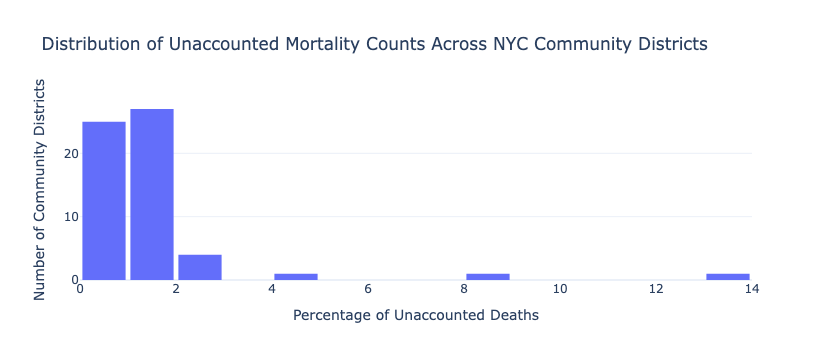

In [25]:
import plotly.express as px

mortality_diagnostic["Percent_Unaccounted"] = (
    mortality_diagnostic["Unaccounted_Deaths"]
    / mortality_diagnostic["Total_Deaths"]
) * 100

fig = px.histogram(
    mortality_diagnostic,
    x="Percent_Unaccounted",
    nbins=15,
    title="Distribution of Unaccounted Mortality Counts Across NYC Community Districts",
    labels={
        "Percent_Unaccounted": "Percentage of Unaccounted Deaths"
    }
)

fig.update_layout(
    template="plotly_white",
    yaxis_title="Number of Community Districts",
    bargap=0.1
)

fig.show()

In [26]:
older_age_groups = ["65_74", "75_84", "85_Plus"]

older_mortality_df = age_adjusted_df[
    ["Community_District"] +
    [f"{age}_Population" for age in older_age_groups] +
    [f"{age}_Deaths" for age in older_age_groups]
].copy()

older_mortality_df.head()

,Community_District,65_74_Population,75_84_Population,85_Plus_Population,65_74_Deaths,75_84_Deaths,85_Plus_Deaths
0,101,3622,2178,1048,23,47,72
1,102,8832,4784,1342,50,116,165
2,103,17241,8449,4681,201,283,463
3,104,12002,5533,1696,120,141,172
4,105,5141,2227,1077,43,60,72


In [27]:
print(older_mortality_df.isna().sum())

assert len(older_mortality_df) == 59
assert older_mortality_df.notna().all().all()

Community_District    0
65_74_Population      0
75_84_Population      0
85_Plus_Population    0
65_74_Deaths          0
75_84_Deaths          0
85_Plus_Deaths        0
dtype: int64


In [28]:
older_mortality_df["Population_65_Plus"] = (
    older_mortality_df[
        [f"{age}_Population" for age in older_age_groups]
    ].sum(axis=1)
)

older_mortality_df["Deaths_65_Plus"] = (
    older_mortality_df[
        [f"{age}_Deaths" for age in older_age_groups]
    ].sum(axis=1)
)

older_mortality_df.head()

,Community_District,65_74_Population,75_84_Population,85_Plus_Population,65_74_Deaths,75_84_Deaths,85_Plus_Deaths,Population_65_Plus,Deaths_65_Plus
0,101,3622,2178,1048,23,47,72,6848,142
1,102,8832,4784,1342,50,116,165,14958,331
2,103,17241,8449,4681,201,283,463,30371,947
3,104,12002,5533,1696,120,141,172,19231,433
4,105,5141,2227,1077,43,60,72,8445,175


In [29]:
older_standard_weights = {
    "65_74": 0.066037,
    "75_84": 0.044842,
    "85_Plus": 0.015508
}

total_weight = sum(older_standard_weights.values())

older_standard_weights = {
    age: weight / total_weight
    for age, weight in older_standard_weights.items()
}

print(older_standard_weights)
print("Sum:", sum(older_standard_weights.values()))

{'65_74': 0.5224983582172217, '75_84': 0.35479914864661716, '85_Plus': 0.12270249313616115}
Sum: 1.0


In [30]:
for age in older_age_groups:

    assert older_mortality_df[f"{age}_Population"].gt(0).all()
    assert older_mortality_df[f"{age}_Deaths"].ge(0).all()

    older_mortality_df[f"{age}_Rate"] = (
        older_mortality_df[f"{age}_Deaths"]
        / older_mortality_df[f"{age}_Population"]
    ) * 1000

older_mortality_df.head()

,Community_District,65_74_Population,75_84_Population,85_Plus_Population,65_74_Deaths,75_84_Deaths,85_Plus_Deaths,Population_65_Plus,Deaths_65_Plus,65_74_Rate,75_84_Rate,85_Plus_Rate
0,101,3622,2178,1048,23,47,72,6848,142,6.350083,21.579431,68.702290
1,102,8832,4784,1342,50,116,165,14958,331,5.661232,24.247492,122.950820
2,103,17241,8449,4681,201,283,463,30371,947,11.658256,33.495088,98.910489
3,104,12002,5533,1696,120,141,172,19231,433,9.998334,25.483463,101.415094
4,105,5141,2227,1077,43,60,72,8445,175,8.364131,26.942075,66.852368


In [31]:
for age in older_age_groups:

    older_mortality_df[f"{age}_Weighted_Rate"] = (
        older_mortality_df[f"{age}_Rate"]
        * older_standard_weights[age]
    )

In [32]:
older_mortality_df["Age_Adjusted_Death_Rate_65_Plus"] = (
    older_mortality_df[
        [f"{age}_Weighted_Rate" for age in older_age_groups]
    ].sum(axis=1, min_count=3)
)

In [33]:
older_mortality_df["Crude_Death_Rate_65_Plus"] = (
    older_mortality_df["Deaths_65_Plus"]
    / older_mortality_df["Population_65_Plus"]
) * 1000

In [34]:
older_mortality_df["Rate_Difference"] = (
    older_mortality_df["Age_Adjusted_Death_Rate_65_Plus"]
    - older_mortality_df["Crude_Death_Rate_65_Plus"]
)

In [35]:
final_older_mortality_df = older_mortality_df[
    [
        "Community_District",
        "Population_65_Plus",
        "Deaths_65_Plus",
        "Crude_Death_Rate_65_Plus",
        "Age_Adjusted_Death_Rate_65_Plus",
        "Rate_Difference"
    ]
].copy()

final_older_mortality_df.round(2)

,Community_District,Population_65_Plus,Deaths_65_Plus,Crude_Death_Rate_65_Plus,Age_Adjusted_Death_Rate_65_Plus,Rate_Difference
0,101,6848,142,20.74,19.40,-1.33
1,102,14958,331,22.13,26.65,4.52
2,103,30371,947,31.18,30.11,-1.07
3,104,19231,433,22.52,26.71,4.19
4,105,8445,175,20.72,22.13,1.41
5,106,29114,615,21.12,19.17,-1.95
6,107,47298,1189,25.14,23.70,-1.44
7,108,49343,1161,23.53,20.73,-2.79
8,109,15694,416,26.51,28.11,1.61
9,110,16254,548,33.71,35.93,2.22


In [36]:
final_older_mortality_df.to_csv(
    "AgeAdjustedMortality65Plus2023.csv",
    index=False
)

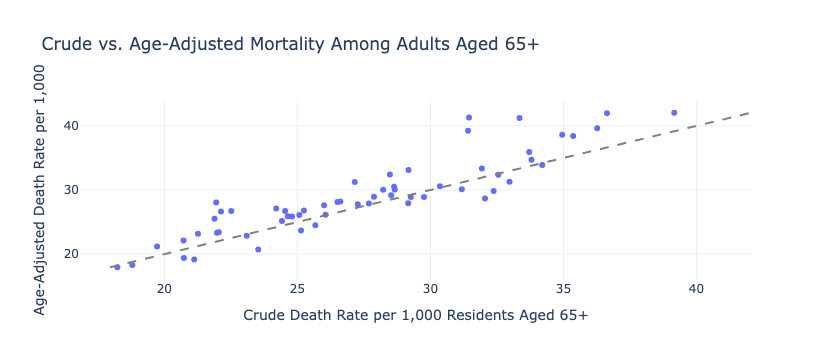

In [37]:
import plotly.express as px

fig = px.scatter(
    final_older_mortality_df,
    x="Crude_Death_Rate_65_Plus",
    y="Age_Adjusted_Death_Rate_65_Plus",
    hover_name="Community_District",
    hover_data=[
        "Population_65_Plus",
        "Deaths_65_Plus",
        "Rate_Difference"
    ],
    title="Crude vs. Age-Adjusted Mortality Among Adults Aged 65+",
    labels={
        "Crude_Death_Rate_65_Plus":
            "Crude Death Rate per 1,000 Residents Aged 65+",
        "Age_Adjusted_Death_Rate_65_Plus":
            "Age-Adjusted Death Rate per 1,000"
    }
)

minimum = min(
    final_older_mortality_df["Crude_Death_Rate_65_Plus"].min(),
    final_older_mortality_df["Age_Adjusted_Death_Rate_65_Plus"].min()
)

maximum = max(
    final_older_mortality_df["Crude_Death_Rate_65_Plus"].max(),
    final_older_mortality_df["Age_Adjusted_Death_Rate_65_Plus"].max()
)

fig.add_shape(
    type="line",
    x0=minimum,
    y0=minimum,
    x1=maximum,
    y1=maximum,
    line=dict(color="gray", dash="dash")
)

fig.update_layout(template="plotly_white")

fig.show()

In [38]:
mortality_65_export = older_mortality_df[
    [
        "Community_District",
        "Population_65_Plus",
        "Deaths_65_Plus",
        "Crude_Death_Rate_65_Plus",
        "Age_Adjusted_Death_Rate_65_Plus"
    ]
].copy()

mortality_65_export.to_csv(
    "MortalityRates65Plus2023.csv",
    index=False
)

mortality_65_export.head()

,Community_District,Population_65_Plus,Deaths_65_Plus,Crude_Death_Rate_65_Plus,Age_Adjusted_Death_Rate_65_Plus
0,101,6848,142,20.735981,19.404214
1,102,14958,331,22.128627,26.647346
2,103,30371,947,31.181061,30.112012
3,104,19231,433,22.515730,26.709509
4,105,8445,175,20.722321,22.132222


In [39]:
import pandas as pd

death_rate_df = pd.read_csv(
    "Deathratebycommunitydistrict.csv"
)

death_rate_df.head()

,commntydst,Total_population,Total_Deaths,Death_Rate
0,101,78390,181,2.308968
1,102,92445,398,4.305263
2,103,163141,1287,7.888881
3,104,131351,677,5.154129
4,105,63600,254,3.993711


In [40]:
mortality_65_export = mortality_65_export.rename(
    columns={"Community_District": "commntydst"}
)

death_rate_df["commntydst"] = (
    death_rate_df["commntydst"].astype(int)
)

mortality_65_export["commntydst"] = (
    mortality_65_export["commntydst"].astype(int)
)

In [41]:
combined_mortality_df = death_rate_df.merge(
    mortality_65_export,
    on="commntydst",
    how="left",
    validate="one_to_one"
)

combined_mortality_df.head()

,commntydst,Total_population,Total_Deaths,Death_Rate,Population_65_Plus,Deaths_65_Plus,Crude_Death_Rate_65_Plus,Age_Adjusted_Death_Rate_65_Plus
0,101,78390,181,2.308968,6848,142,20.735981,19.404214
1,102,92445,398,4.305263,14958,331,22.128627,26.647346
2,103,163141,1287,7.888881,30371,947,31.181061,30.112012
3,104,131351,677,5.154129,19231,433,22.515730,26.709509
4,105,63600,254,3.993711,8445,175,20.722321,22.132222


In [42]:
print("Number of rows:", len(combined_mortality_df))

print("\nMissing values:")
print(combined_mortality_df.isna().sum())

Number of rows: 59

Missing values:
commntydst                         0
Total_population                   0
Total_Deaths                       0
Death_Rate                         0
Population_65_Plus                 0
Deaths_65_Plus                     0
Crude_Death_Rate_65_Plus           0
Age_Adjusted_Death_Rate_65_Plus    0
dtype: int64


In [44]:
combined_mortality_df.to_csv(
    "CombinedDeathRatesByCommunityDistrict2023.csv",
    index=False
)